# Siparişler - `review_score` Çok Değişkenli Regresyonu

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Import modules
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

⚠️ Devam etmeden önce:
* 💾 Önceki ünitenin Siparişler çözümünü indirin
* 👥 `order_solution.py`'nin içeriğini `olist/order.py` dosyasına kopyalayıp yapıştırın

⚠️ `olist` havuzunuzda `order.py` dosyasındaki kod değişikliklerini commit etmeyi unutmayın!

👇 Öncelikle `orders` veri setini içeri aktarın

In [3]:
from olist.order import Order
orders = Order().get_training_data(with_distance_seller_customer=True)

Önceki analizimizi hatırlayalım:

Aşağıdaki 👇 korelasyon matrisi üzerinden, `review_score`'un çoğunlukla iki özellik ile ilişkili olduğunu görebiliriz: `wait_time` ve `delay_vs_expected`. Ancak, bu iki özellik de birbirleriyle yüksek oranda ilişkilidirler.

Bu alıştırmada, bir özelliğin etkisini ayırt etmek için `statsmodels` kullanacağız, **diğer özellikleri sabit tutarak**.

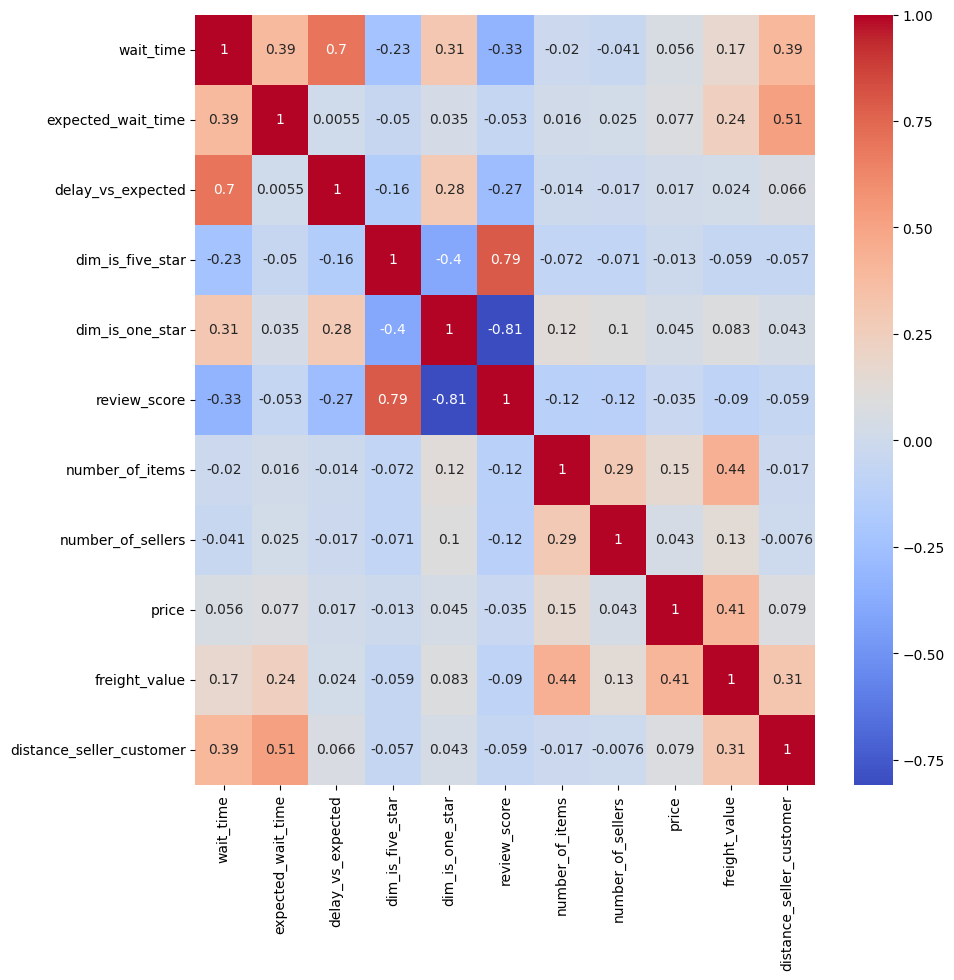

In [4]:
plt.figure(figsize = (10, 10))

sns.heatmap(
    orders.corr(numeric_only=True),
    cmap='coolwarm',
    annot=True,
    annot_kws={"size": 10}
);

## 1 - Tek Değişkenli Regresyon

❓ [statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html) ile `statsmodels.formula.api` kullanarak hızlı bir şekilde şunları oluşturun:
 - `model1`: `review_score`'un `wait_time` üzerinde ols regresyonu
 - `model2`: `review_score`'un `delay_vs_expected` üzerinde ols regresyonu

Her biri için `summary` tablosunu yazdırın ve sonuçları yorumlayin:
- Bu sonuçların seaborn regplot sonuçları ile nasıl eşleştiğini anladığınızdan emin olun
- Regresyon performans metriği `R-squared`, `individual regression coefficients`, `t-values`, `p-values` ve `95% confidence intervals`'ı okuyun

***Model 1***:

In [16]:
import statsmodels.formula.api as smf

model_wait = smf.ols('review_score ~ wait_time', data=orders).fit()
print(model_wait.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.112
Model:                            OLS   Adj. R-squared:                  0.112
Method:                 Least Squares   F-statistic:                 1.204e+04
Date:                Sat, 15 Aug 2026   Prob (F-statistic):               0.00
Time:                        11:09:18   Log-Likelihood:            -1.5441e+05
No. Observations:               95872   AIC:                         3.088e+05
Df Residuals:                   95870   BIC:                         3.089e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.7236      0.006    727.904      0.0

wait_time katsayısı = -0.0454: Daha önceki Seaborn analizindeki eğim tahminimizle (-0.05) tutarlı — her ek bekleme günü, review skorunu ortalama 0.045 puan düşürüyor.
P>|t| = 0.000: p-value pratikte sıfıra çok yakın (0.05'ten çok küçük) — bu ilişki istatistiksel olarak son derece anlamlı, tesadüfen ortaya çıkmış olma ihtimali yok denecek kadar az.
%95 güven aralığı = [-0.046, -0.045]: Çok dar bir aralık — bu da 95.872 gözlem gibi büyük bir örneklem sayesinde, gerçek eğimin nerede olduğundan çok eminiz demek.
R² = 0.112: wait_time tek başına, review_score'daki varyansın sadece %11.2'sini açıklıyor — yani ilişki istatistiksel olarak güçlü/anlamlı olsa da, review skorunu belirleyen tek faktör bu değil, başka birçok faktör de devrede.

***Model 2***:

In [17]:
model_delay = smf.ols('review_score ~ delay_vs_expected', data=orders).fit()
print(model_delay.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.074
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     7681.
Date:                Sat, 15 Aug 2026   Prob (F-statistic):               0.00
Time:                        11:09:41   Log-Likelihood:            -1.5639e+05
No. Observations:               95872   AIC:                         3.128e+05
Df Residuals:                   95870   BIC:                         3.128e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.2121      0.00

Bu, Seaborn görsel analizindeki bulguyu doğruluyor: delay_vs_expected'in etkisi (katsayı büyüklüğü olarak) wait_time'dan daha güçlü (-0.075 vs -0.045) — yani beklenen tarihten sonra geçen her gün, ham bekleme süresinin her gününden ~%65 daha fazla review puanını düşürüyor. Ama ilginç bir nokta: R² açısından wait_time daha güçlü (0.112 vs 0.074) — yani wait_time tek başına review skorundaki varyansı biraz daha iyi açıklıyor, katsayısı daha küçük olsa da.

## 2 - Çok Değişkenli Regresyon

❓ Siparişe bir gün `delay_vs_expected` eklemenin `review_score` üzerindeki etkisi nedir, **`wait_time` sabit tutarak**? İki özellikten hangisi düşük `review_score` için en açıklayıcıdır?

Bu amaçla, `wait_time` ve `delay_vs_expected`'in özellikler (bağımsız değişkenler) olduğu ve `review_score`'un hedef (bağımlı değişken) olduğu bir OLS modeli `model3`'ü çalıştırın

***Model 3***:

In [18]:
model_multi = smf.ols('review_score ~ wait_time + delay_vs_expected', data=orders).fit()
print(model_multi.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.114
Model:                            OLS   Adj. R-squared:                  0.114
Method:                 Least Squares   F-statistic:                     6191.
Date:                Sat, 15 Aug 2026   Prob (F-statistic):               0.00
Time:                        11:10:03   Log-Likelihood:            -1.5426e+05
No. Observations:               95872   AIC:                         3.085e+05
Df Residuals:                   95869   BIC:                         3.086e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             4.6502      0.00

Her iki değişken de hâlâ istatistiksel olarak anlamlı (p ≈ 0), ama delay_vs_expected'in etkisi çok değişkenli modelde ciddi şekilde küçüldü (-0.075 → -0.021). Bunun nedeni: wait_time ve delay_vs_expected birbiriyle güçlü korelasyonlu (biri diğerinin neredeyse bir bileşeni — çünkü gecikme, zaten beklenenden uzun süren bir bekleme süresi anlamına geliyor). Tek başına baktığımızda delay_vs_expected sanki daha güçlü bir etki gösteriyormuş gibi görünüyordu, ama aslında bu etkinin büyük kısmı wait_time ile paylaşılan (ortak) bilgiden geliyormuş — çok değişkenli model bu ayrımı netleştirdi: wait_time'ın bağımsız etkisi (-0.038), delay_vs_expected'in bağımsız etkisinden (-0.021) daha güçlü çıktı.

R² = 0.114: İki değişken birlikte bile, review_score'daki varyansın sadece %11.4'ünü açıklıyor — tek değişkenli wait_time modelinden (0.112) çok az daha iyi. Bu, delay_vs_expected'in wait_time'a ek olarak çok az yeni bilgi kattığını gösteriyor (multicollinearity'nin bir işareti).

----
👉 Çok değişkenli regresyon, bir özelliğin etkisini izole etmek ve diğer özelliklerin etkisini kontrol etmek için bize izin verir. Bu yeni katsayılara **`kısmi korelasyon katsayıları`** denir. 

❓ Yukarıda *seaborn* ile hesaplanan **basit regresyon** katsayıları ile fark görebilir misiniz? 

❓ `wait_time` ve `delay_vs_expected` için göreceli eğimler hakkında ne söyleyebilirsiniz?

<details>
    <summary>- 💡 Solution 💡-</summary>

- Holding `wait_time` constant, each additional day of `delay` reduces the review_score on average by 0.0205 [0.023 - 0.018] points
- Holding `delay` constant, each additional day of `wait_time` reduces the review_score on average by 0.0383 [0.039 - 0.037] points

Contrary to what was found with the simple bivariate correlation analysis, `delay` is actually less impactful than `wait_time` in driving lower `review_score`! This interesting finding demonstrates the importance of multi-variate regression to remove the potential impact of confounding factors

---
❌ R-squared oldukça düşük: review_score varyasyonlarının en fazla %12'si `wait_time` ve `delay_vs_expected`'in birleşik varyasyonları tarafından açıklanır.

✅ Doğrusal regresyonun açıklanabilirliğini iyileştirmek için regresyonumuza daha fazla özellik eklemeyi deneyelim.

Sonraki adımlarda `orders` veri setinden daha fazla özellik içeren yeni bir OLS `model4` oluşturacağız. Adım adım size rehberlik edeceğiz.

📝 <u>Not</u>: bir **`Çok Değişkenli Doğrusal Regresyon`** aynı zamanda **`Ordinary Least Squares`** yöntemi olarak da adlandırılır çünkü bu modelde **`MSE Ortalama Kare Hatalar`**'ı minimize etmek istiyoruz

***Model 4***:

❓ Hangi özellikleri göz önünde almak istersiniz?

👉 Bu özelliklerle bir `features` DataFrame oluşturun.

- ⚠️ **veri sızıntısı** oluşturmayın: `review_score`'tan doğrudan türetilen özellikleri eklemeyin
- ⚠️ Birbirleriyle mükemmel bir şekilde ilişkili olan iki özellik eklemeyin

In [20]:
features = orders[['wait_time', 'delay_vs_expected', 'number_of_items', 
                    'number_of_sellers', 'price', 'freight_value', 
                    'distance_seller_customer']]

features.head()

,wait_time,delay_vs_expected,number_of_items,number_of_sellers,price,freight_value,distance_seller_customer
0,8.436574,0.0,1,1,29.99,8.72,18.063837
1,13.782037,0.0,1,1,118.70,22.76,856.292580
2,9.394213,0.0,1,1,159.90,19.22,514.130333
3,13.208750,0.0,1,1,45.00,27.20,1822.800366
4,2.873877,0.0,1,1,19.90,8.72,30.174037


Sonra, özellikleri "standardize" edeceğiz.

**Bu ne anlama gelir?**

⚖️  Her özellik $X_i$'yi ilgili z-score'una $Z_i = \frac{X_i - \mu_i}{\sigma_i}$ dönüştüreceğiz.

**Neden?**

Bir `çok değişkenli doğrusal regresyon`'da, her özelliğin hedef üzerindeki etkisini ölçmeye çalışıyoruz.
    
⚠️ Ölçek etkileri nedeniyle, bazı özellikler yanlışlıkla diğerlerinden daha önemli olarak görülecektir
    
> Örneğin: "yatak odası sayısı" özelliği 1 ile 5 arasında ve "yüzey" özelliği 20 ile 200 m² arasında ise, bu iki özelliğin aralıkları oldukça farklıdır...

Bu nedenle kısmi regresyon katsayıları $\beta_i$'yi birlikte karşılaştırabilmek için standardize ederiz. Aksi takdirde, $\beta_i$ aynı boyuta sahip olmayacak, yani elmalar (örn. "gün başına review-yıldızlar") ile portakalları (örn. "BRL başına review-yıldızlar") karşılaştırmış olacaksınız!

📅 Makine Öğrenmesi Algoritmalarını keşfettiğimizde, herhangi bir hedefi tahmin etmeye çalışmadan önce bazı ölçekleme işlemleri gerçekleştirmemiz gerekecektir.

👉  Özelliklerinizi standardize edin:

1. `features` DataFrame'inizden başlayın
1. `mean`'i çıkarın
1. Standart sapma `std`'ye bölün.
1. Sonucu `orders_standardized` değişkenine kaydedin.
1. Son olarak, `orders['review_score']` sütununu `orders_standardized`'e kopyalayın.

2. ve 3. adımları basit bir matematiksel işlem olarak yazabilirsiniz, hatta DataFrames ile de. Pandas bunu anlamak için yeterince akıllıdır.

<details>
  <summary><i>İpucu</i></summary>

  ```python
  features - features.mean() / features.std()
  ```

</details>

👉 `model4`'ü oluşturun ve eğitin.

In [21]:
import statsmodels.api as sm

X = sm.add_constant(features)
y = orders['review_score']

model4 = sm.OLS(y, X).fit()
print(model4.summary())

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.145
Method:                 Least Squares   F-statistic:                     2322.
Date:                Sat, 15 Aug 2026   Prob (F-statistic):               0.00
Time:                        11:11:32   Log-Likelihood:            -1.5258e+05
No. Observations:               95872   AIC:                         3.052e+05
Df Residuals:                   95864   BIC:                         3.052e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

R² gelişimi

0.114 → 0.145 — daha fazla feature eklemek işe yaradı, ama hâlâ oldukça düşük (review_score varyansının sadece %14.5'i açıklanıyor).

Katsayı anlamlılığı — dikkat çeken nokta

Tüm feature'lar anlamlı değil:

price (p=0.486) ve freight_value (p=0.385): p-value'ları 0.05'in çok üzerinde — bunlar istatistiksel olarak anlamlı değil, yani review_score üzerinde gerçek bir etkileri olduğuna dair yeterli kanıt yok, katsayıları pratikte sıfırdan ayırt edilemiyor.
Geri kalan tüm feature'lar (wait_time, delay_vs_expected, number_of_items, number_of_sellers, distance_seller_customer) p≈0 ile güçlü şekilde anlamlı.
İlginç bulgular
number_of_sellers katsayısı = -1.063: Çok güçlü bir negatif etki — bir siparişte birden fazla satıcı olması review skorunu ciddi şekilde düşürüyor (muhtemelen koordinasyon/teslimat karmaşıklığı nedeniyle).
number_of_items katsayısı = -0.242: Daha fazla ürün içeren siparişler de biraz daha düşük puan alıyor.

---
❓ En önemli özellikler nelerdir? (onları iyi görselleştirmek için `.plot(kind='barh')` ile bir çubuk grafik yapın)
- Genel regresyon performansı nasıl değişti?
- Bu regresyon istatistiksel olarak anlamlı mıdır?

Genel regresyon performansı nasıl değişti?
R² 0.114'ten 0.145'e yükseldi — daha fazla feature eklemek modelin açıklama gücünü artırdı, ama hâlâ görece düşük (review_score'un %85'i başka faktörlerle açıklanıyor).

Bu regresyon istatistiksel olarak anlamlı mıdır?
Genel model (F-statistic, Prob (F-statistic) = 0.00) olarak kesinlikle anlamlı — yani feature'ların birlikte review_score üzerinde gerçek bir etkisi var. Ancak her feature ayrı ayrı anlamlı değil — price (p=0.486) ve freight_value (p=0.385) istatistiksel olarak anlamsız çıktı, bunlar modelden çıkarılabilir.

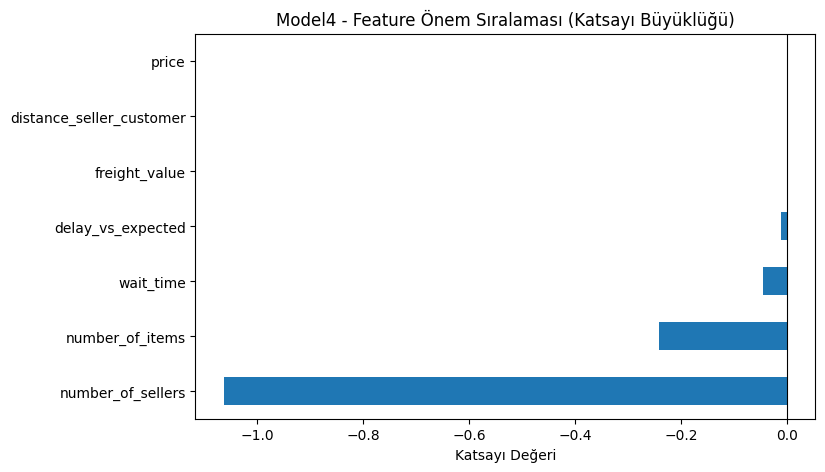

In [22]:
coefs = model4.params.drop('const')

coefs_sorted = coefs.reindex(coefs.abs().sort_values(ascending=False).index)

coefs_sorted.plot(kind='barh', figsize=(8, 5))
plt.xlabel('Katsayı Değeri')
plt.title('Model4 - Feature Önem Sıralaması (Katsayı Büyüklüğü)')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.show()

Grafik beklediğimiz gibi net bir resim çiziyor. number_of_sellers açık ara en baskın feature — katsayı büyüklüğü diğer feature'ların çoğundan kat kat fazla. Onu number_of_items takip ediyor. Diğer feature'lar (wait_time, delay_vs_expected, freight_value, distance_seller_customer, price) katsayı büyüklüğü olarak görece küçük — grafikte neredeyse görünmeyecek kadar ince çubuklar.

Bu, katsayı büyüklüğünün ölçek farklarından da etkilendiğini hatırlatıyor önemli bir nokta: distance_seller_customer gibi geniş aralıklı (0'dan binlerce km'ye kadar) bir değişkenin katsayısı küçük görünebilir ama toplam etkisi (katsayı × tipik değer aralığı) hâlâ önemli olabilir — oysa number_of_sellers genelde 1-3 gibi dar bir aralıkta değiştiği için katsayısının büyük olması, "bu feature değiştiğinde review_score çok değişir" anlamına geliyor. Gerçek göreceli önemi adil karşılaştırmak istersek, feature'ları standartlaştırıp (z-score) sonra katsayılara bakmak daha doğru olurdu — istersen bunu da deneyebiliriz.

<details>
    <summary>- 💡 Açıklamalar 💡 -</summary>
    

- `wait_time` en büyük açıklayıcı değişkendir
- Tek bir sipariş için ne kadar çok `items` ve `sellers` varsa, `review_score` o kadar düşük görünür
- Mesafe de müşteri memnuniyetinde rol oynar.
- Özellik seçiminize bağlı olarak, `price` ve `freight_value` hakkında p-değerleri çok yüksekse hiçbir sonuca varamayabilirsiniz
    
- Genel olarak, bu çok değişkenli regresyon, F-istatistiği 1'den çok daha büyük olduğu için istatistiksel olarak anlamlı kalır (en az bir özelliğin çok düşük p-değeri vardır)

- R-squared çok fazla artmadı. `review_score`'un açıklanabilirliğinin çoğu orders veri seti dışında yer alır.

⚠️ Gözlem sayısı (n) özellik sayısından (p) çok daha yüksek olduğunda düşük R-squared yaygındır. Böyle regresyonlardan, istatistiksel olarak anlamlı olması koşuluyla yine de ilgili içgörüler elde edilebilir.
</details>



## 3 - Model Performansını Kontrol Edin

⚠️ Regresyon performansı sadece R-squared'i ile ölçülmemelidir!

👀 Her zaman tahminlerin dağılımını, özellikle de kalıntıları görselleştirin.

❓ Kalıntıları hesaplayın.

Kalıntıların ortalamasının 0'a eşit olduğunu görmelisiniz (doğrusal regresyon yapılırken bunu her zaman doğrulayın)

In [23]:
residuals = model4.resid
residuals.mean()

np.float64(-3.903419643588635e-15)

🧮 İlişkili RMSE'yi hesaplayın.

In [24]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(orders['review_score'], model4.fittedvalues))
rmse

np.float64(1.1883154116821097)

📊 `residuals`'ı bir histogramda çizin.

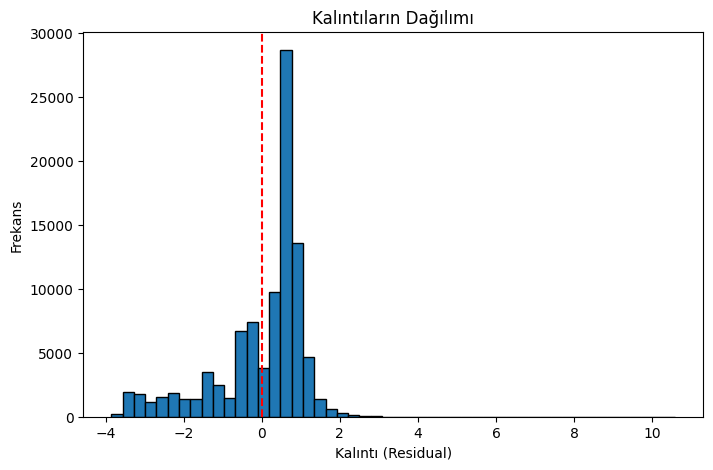

In [25]:
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50, edgecolor='black')
plt.axvline(x=0, color='red', linestyle='--')
plt.xlabel('Kalıntı (Residual)')
plt.ylabel('Frekans')
plt.title('Kalıntıların Dağılımı')
plt.show()

❓ Kalıntıların distplot'unun neden bu kadar garip bir şekle sahip olduğunu tahmin edebilir misiniz?

*İpucu:*<br/>
👉 Aynı grafik üzerinde hem `review_score`'un dağılımını hem de `predicted_review_score`'un dağılımını çizin.

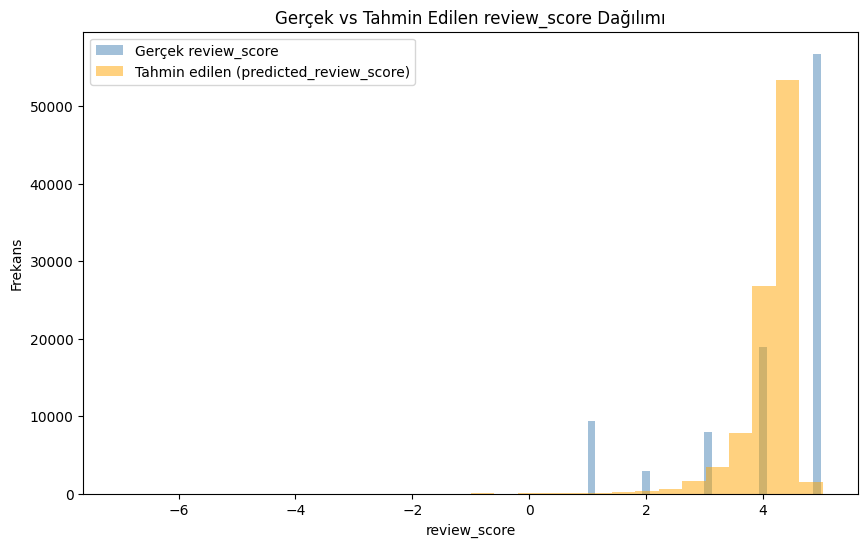

In [26]:
predicted_review_score = model4.fittedvalues

plt.figure(figsize=(10, 6))
plt.hist(orders['review_score'], bins=30, alpha=0.5, label='Gerçek review_score', color='steelblue')
plt.hist(predicted_review_score, bins=30, alpha=0.5, label='Tahmin edilen (predicted_review_score)', color='orange')
plt.xlabel('review_score')
plt.ylabel('Frekans')
plt.legend()
plt.title('Gerçek vs Tahmin Edilen review_score Dağılımı')
plt.show()

Gerçek review_score (mavi): Sadece 5 keskin, dar çubukta — tam olarak 1, 2, 3, 4, 5 değerlerinde yoğunlaşmış. Verinin ezici çoğunluğu 5 puanında (en yüksek mavi çubuk).

Tahmin edilen değerler (turuncu): Sürekli bir aralığa yayılmış (özellikle 3.5-5 arası) — model hiçbir zaman tam olarak "5" tahmin edemiyor, bunun yerine 4.2, 4.5 gibi ondalıklı değerler üretiyor çünkü doğrusal regresyon matematiksel olarak sürekli bir çıktı üretmeye mahkum.

Neden bu sorun oluşuyor

Model, gerçek dağılımın (5 puanda çok yoğun bir küme) şeklini fiziksel olarak taklit edemiyor — çünkü bir doğru denklemi (y = a + b*x), girdi değerleri ne olursa olsun sürekli bir çıktı üretir. Bu yüzden:

En sık görülen sınıf olan 5, modelin ortalamaya doğru "çekilmesi" nedeniyle hep hafif hafife tahmin ediliyor (turuncu dağılım 5'in solunda toplanmış).
Nadir görülen düşük skorlar (1, 2) neredeyse hiç tahmin edilmiyor — model onları pratikte "göremiyor" çünkü optimize ettiği MSE, çoğunluk sınıfına (5) yakın kalmayı ödüllendiriyor.

Bu, kalıntı histogramındaki çarpıklığın tam kaynağı: gerçek değer 5 olduğunda ama model 4.2 tahmin ettiğinde, kalıntı +0.8 civarında yığılıyor — bu da o "keskin tepe" şeklini oluşturuyor.

Sonuç: Bu, doğrusal regresyonun review_score gibi yoğun, dengesiz (imbalanced) ve kesikli bir hedef için neden uygun olmadığının görsel kanıtı — daha önce önerdiğim gibi ordinal classification veya en azından class-aware bir yaklaşım (örn. class weighting ile classification) burada çok daha isabetli olurdu.

📈 Aslında, önceki zorlukta `review_score`'un `delay_vs_expected`'e karşı `regresyon çizgisi`'ni zaten çizmiştik.

Bu çizimi yeniden görselleştirmek için aşağıdaki hücreyi çalıştırın:

(0.0, 5.940358949745317)

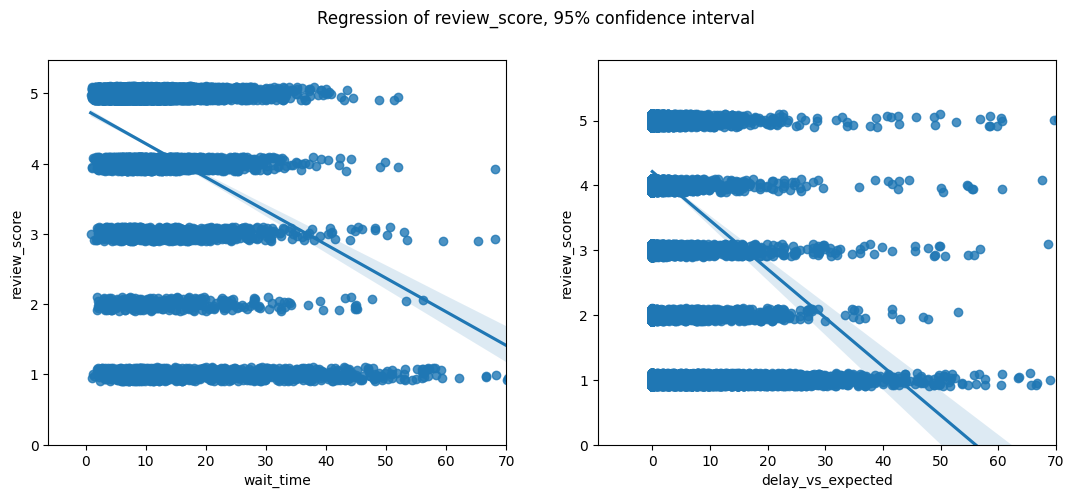

In [15]:
sample = orders.sample(10000, random_state=42)
plt.figure(figsize=(13,5))
plt.suptitle('Regression of review_score, 95% confidence interval')
plt.subplot(1,2,1)
sns.regplot(x = sample.wait_time, y= sample.review_score, y_jitter=.1, ci=95)
plt.xlim(right=70)
plt.ylim(bottom=0)

plt.subplot(1,2,2)
sns.regplot(x = orders.delay_vs_expected, y= orders.review_score, y_jitter=.1, ci=95)
plt.xlim(right=70)
plt.ylim(bottom=0)

☝️ Bir siparişin `review_score`'unu onun `wait_time` veya `delay_vs_expected`'ine karşı regrese etmenin zor olduğunu görebilirsiniz çünkü `review_score` ayrı bir sayı olup aynı zamanda bir kategori olarak da yorumlanabilir: 1 (çok kötü), 2 (kötü), 3 (orta), 4 (iyi), 5 (mükemmel).

📅 Sonraki ünitede, adına rağmen bir `Classification Algorithm` olan yeni bir model keşfedeceksiniz: `Logistic Regression` 

☝️ Sonuç olarak, modelimiz iki nedenden dolayı o kadar harika değil:
- İlk olarak, review_scores'un önemli bir kısmını açıklamak için yeterli özelliğimiz olmadığı için (düşük R-squared)
- İkinci olarak, "doğrusal regresyon" işlevini ayrı bir sınıflandırma problemine uydurmaya çalıştığımız için

💡 Bireysel siparişler üzerinde çalışmak ve `wait_time` tabanlı ayrı `review_score`'ları açıklamaya çalışmak yerine, bir sonraki zorlukta siparişleri satıcılar tarafından toplayarak analiz edilmesini satıcı seviyesine yoğunlaştıracağız.

🏁 Harika iş!

💾 İşiniz bittiğinde bu not defterini *kaydetmeyi*, *commit* ve *push* etmeyi unutmayın!